# Evaluation: Logistic Regression on the 200k Dataset (cmu + synthetic)

## 1. Introduction

This notebook covers steps 4 (**Evaluate**) and 5 (**Predict**) for the 200k model. It follows `05_modeling_logreg/03_evaluate` section by section, so the two models are scored in exactly the same way. In this notebook we:

1. Load the model saved by `02_train` (it is **not retrained**) and the test set, which is opened for the first time here.
2. Predict on the test set and score the model at two thresholds: the default 0.50 and the threshold chosen in `02_train`.
3. Report accuracy, precision, recall, F1 and specificity, the confusion matrix, the classification report and the ROC curve.
4. Compare training and test scores, and compare the model with the baselines.
5. Measure the uncertainty, the calibration, the per-1,000 view and the behaviour across sex and age groups.
6. Use the model on new, hypothetical respondents.

### Rules for the test set
- The test set is `diabetes_model_test`: **the same 14,039 real people as for the 70k model.** This is what makes the comparison fair. It contains **no synthetic rows**.
- The model, its features and its threshold were **fixed in `02_train`**. Nothing is changed after looking at the results here.
- If a result is disappointing, we report and discuss it. We do not tune the model on the test set.
- The training table is read **only to score the saved model on it** and to fit the baselines.

### What a believable result looks like
The cross-validation scores in `02_train` (ROC AUC about 0.81, computed on real validation people) tell us what to expect: test scores close to them. A test score clearly *above* them would be a warning sign of leakage.

**Inputs:** `logreg_200k.joblib`, `diabetes_model_test`, `diabetes_cmu_synth_train` | **Output:** a results table for the model comparison notebook

## 2. Import Libraries and Connect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from pathlib import Path

from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

# Settings (the same names and values as in 02_train)
TRAIN_TABLE = "diabetes_cmu_synth_train"
TEST_TABLE = "diabetes_model_test"
RESULTS_TABLE = "diabetes_eval_logreg_200k"
TARGET = "Diabetes_binary"
RANDOM_STATE = 42
REAL_PREVALENCE = 0.14
MODEL_PATH = Path("../../application/models/logreg_200k.joblib")

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))

print("Libraries imported and database connection successful.")

Libraries imported and database connection successful.


## 3. Load the Saved Model and the Data

Checks on the way in: the scikit-learn version, and that **no test row is identical to a training row, real or synthetic**.

In [2]:
bundle = joblib.load(MODEL_PATH)
model = bundle["model"]
FEATURES = bundle["features"]
THRESHOLD = bundle["threshold"]

train_df = pd.read_sql(f"SELECT * FROM {TRAIN_TABLE}", con=engine)
test_df = pd.read_sql(f"SELECT * FROM {TEST_TABLE}", con=engine)
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
is_real = (train_df["is_synthetic"] == 0).to_numpy()

# Leakage check: rows that appear identically in both tables (all 22 columns)
cols = list(test_df.columns)
shared = test_df.merge(train_df[cols].drop_duplicates(), how="inner")

loaded = pd.DataFrame({
    "Item": ["Saved model file", "Features used by the model", "Decision threshold from 02_train",
             "scikit-learn version (saved / current)", "Test rows", "Test: no diabetes / diabetes",
             "Training rows (read only, for scoring)", "of which synthetic",
             "Test rows identical to a training row (real or synthetic)"],
    "Value": [MODEL_PATH.name, len(FEATURES), round(THRESHOLD, 3),
              f"{bundle['sklearn_version']} / {sklearn.__version__}",
              f"{len(test_df):,}", f"{(y_test == 0).sum():,} / {(y_test == 1).sum():,}",
              f"{len(train_df):,}", f"{int(train_df['is_synthetic'].sum()):,}", len(shared)],
})
display(loaded.style.hide(axis="index"))

print("Model and data loaded successfully. The model is NOT retrained in this notebook.")

Item,Value
Saved model file,logreg_200k.joblib
Features used by the model,16
Decision threshold from 02_train,0.376000
scikit-learn version (saved / current),1.9.1 / 1.9.1
Test rows,"14,039"
Test: no diabetes / diabetes,"7,020 / 7,019"
"Training rows (read only, for scoring)","200,000"
of which synthetic,"71,922"
Test rows identical to a training row (real or synthetic),0


Model and data loaded successfully. The model is NOT retrained in this notebook.


## 4. Evaluate. Predict on the Test Set

In [3]:
proba_test = model.predict_proba(X_test)[:, 1]
proba_train = model.predict_proba(X_train)[:, 1]

chosen_label = f"Chosen ({THRESHOLD:.2f})"
thresholds_used = {"Default (0.50)": 0.5, chosen_label: THRESHOLD}
pred_test = {name: (proba_test >= t).astype(int) for name, t in thresholds_used.items()}

preview = pd.DataFrame({
    "Actual": y_test.head(5).values,
    "Probability of diabetes": proba_test[:5].round(3),
    "Predicted at default 0.50": pred_test["Default (0.50)"][:5],
    f"Predicted at {chosen_label}": pred_test[chosen_label][:5],
})
display(preview.style.hide(axis="index"))

print("Predictions on the test set completed.")

Actual,Probability of diabetes,Predicted at default 0.50,Predicted at Chosen (0.38)
0,0.101000,0,0
0,0.350000,0,0
1,0.825000,1,1
1,0.831000,1,1
0,0.256000,0,0


Predictions on the test set completed.


## 5. Accuracy, Precision, Recall and F1

The metrics are the same as in the 70k notebook. **Recall** is our main metric. Precision and accuracy are measured on balanced test data, so they are more optimistic than they would be on a real population. Recall, specificity and ROC AUC are not affected by the balance.

In [4]:
def evaluate(y, proba, threshold):
    """All metrics for one set of rows at one threshold."""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "Accuracy": accuracy_score(y, pred),
        "Recall (sensitivity)": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": tp / (tp + fp),
        "F1": f1_score(y, pred),
        "ROC AUC": roc_auc_score(y, proba),
        "Brier score": brier_score_loss(y, proba),
        "Missed diabetes cases (false negatives)": fn,
        "Healthy people flagged (false positives)": fp,
    }

results = pd.DataFrame({name: evaluate(y_test, proba_test, t) for name, t in thresholds_used.items()})

show = results.round(3).astype(object)
for r in ["Missed diabetes cases (false negatives)", "Healthy people flagged (false positives)"]:
    show.loc[r] = results.loc[r].astype(int).map("{:,}".format)
display(show)

,Default (0.50),Chosen (0.38)
Accuracy,0.724,0.725
Recall (sensitivity),0.727,0.849
Specificity,0.722,0.6
Precision,0.724,0.68
F1,0.725,0.755
ROC AUC,0.8,0.8
Brier score,0.182,0.182
Missed diabetes cases (false negatives),"1,919","1,058"
Healthy people flagged (false positives),"1,949","2,808"


### Interpretation

- **Recall improvement:** The chosen threshold increases Recall from 0.727 to 0.849, reducing missed diabetes cases from 1,919 to 1,058 — **861 fewer missed cases**.
- **Specificity trade-off:** Specificity decreases from 0.722 to 0.600, while false positives increase from 1,949 to 2,808. More people without reported diabetes are flagged.
- **Precision and F1:** Precision decreases from 0.724 to 0.680, but F1 improves from 0.725 to 0.755 because the increase in Recall outweighs the precision decrease in the F1 score.
- **Accuracy:** Accuracy remains nearly unchanged, increasing slightly from 0.724 to 0.725. Accuracy alone does not capture the change in missed cases and false positives.
- **Probability-based metrics:** ROC AUC remains 0.800 and Brier score remains 0.182 because changing the classification threshold changes predicted labels, not the underlying predicted probabilities.
- **Overall:** The chosen threshold prioritizes identifying more potential diabetes cases while accepting more false positives. This is a screening trade-off, not a diagnostic conclusion.

## 6. Confusion Matrix

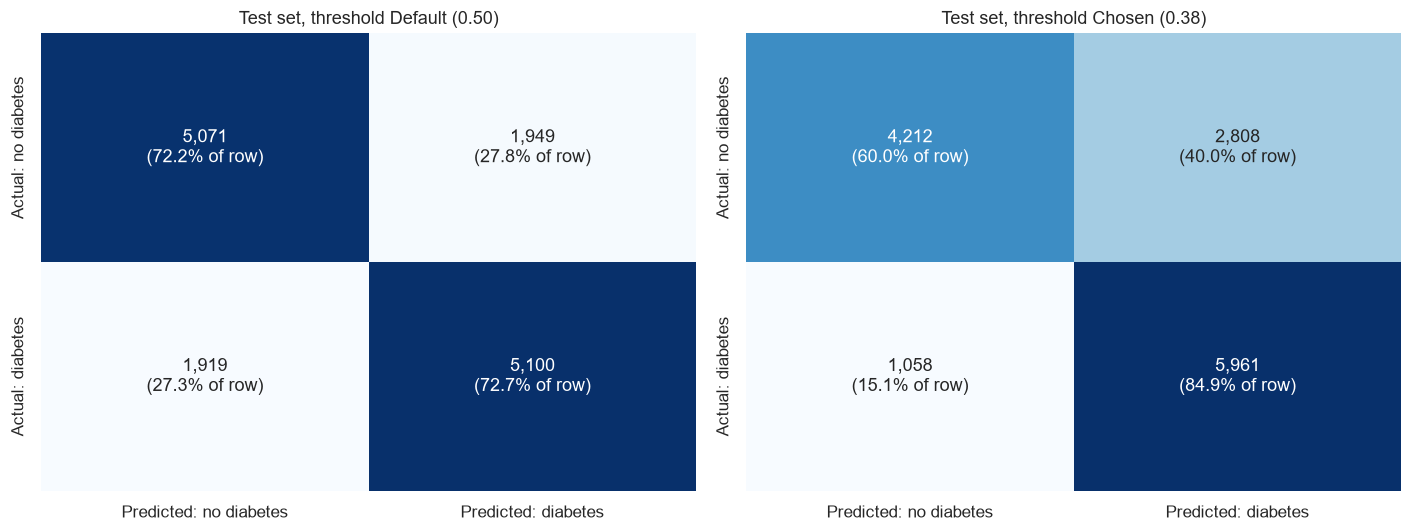

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, t) in zip(axes, thresholds_used.items()):
    cm = confusion_matrix(y_test, pred_test[name])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1f}% of row)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted: no diabetes", "Predicted: diabetes"],
                yticklabels=["Actual: no diabetes", "Actual: diabetes"])
    ax.set_title(f"Test set, threshold {name}")
plt.tight_layout()
plt.show()

### Interpretation

- **Default threshold (0.50):** The model correctly identifies 5,100 people with diabetes and 5,071 people without diabetes. However, it misses 1,919 diabetes cases and incorrectly flags 1,949 people without diabetes.
- **Chosen threshold (0.38):** The model identifies 5,961 people with diabetes and reduces missed cases to 1,058. However, false positives increase to 2,808, while correctly identified people without diabetes decrease to 4,212.
- **Recall improvement:** The proportion of diabetes cases detected increases from 72.7% to 84.9%, reducing missed cases by **861**.
- **Specificity trade-off:** The proportion of people without diabetes correctly identified decreases from 72.2% to 60.0%. The chosen threshold flags a larger proportion of this group as potential cases.
- **Overall:** The chosen threshold prioritizes detecting more potential diabetes cases at the cost of more false positives. This trade-off may be suitable for screening, but flagged individuals would need appropriate follow-up rather than being treated as diagnosed.

## 7. Classification Report

In [6]:
for name in thresholds_used:
    report = pd.DataFrame(classification_report(
        y_test, pred_test[name], target_names=["No diabetes", "Diabetes"], output_dict=True)).T
    print(f"Classification report, threshold {name}:")
    display(report.round(3))

Classification report, threshold Default (0.50):


,precision,recall,f1-score,support
No diabetes,0.725,0.722,0.724,7020.000
Diabetes,0.724,0.727,0.725,7019.000
accuracy,0.724,0.724,0.724,0.724
macro avg,0.724,0.724,0.724,14039.000
weighted avg,0.724,0.724,0.724,14039.000


Classification report, threshold Chosen (0.38):


,precision,recall,f1-score,support
No diabetes,0.799,0.600,0.685,7020.000
Diabetes,0.680,0.849,0.755,7019.000
accuracy,0.725,0.725,0.725,0.725
macro avg,0.740,0.725,0.720,14039.000
weighted avg,0.740,0.725,0.720,14039.000


### Interpretation

- **Default threshold (0.50):** The model has similar precision and recall for both classes, with an F1-score of 0.724 for people without diabetes and 0.725 for people with diabetes.
- **Diabetes detection:** At the chosen threshold (0.38), Recall increases from 0.727 to 0.849, meaning the model identifies a larger proportion of people with reported diabetes.
- **No-diabetes classification:** Recall for the no-diabetes class decreases from 0.722 to 0.600, meaning more people without reported diabetes are incorrectly flagged.
- **Precision trade-off:** Diabetes precision decreases from 0.724 to 0.680. Among those flagged as having diabetes, a smaller proportion actually belong to the diabetes class.
- **F1-score:** The diabetes F1-score improves from 0.725 to 0.755, reflecting the higher Recall despite lower Precision.
- **Overall accuracy:** Accuracy changes only slightly, from 0.724 to 0.725. The classification report shows why accuracy alone does not capture the threshold's impact on each class.

## 8. ROC Curve and ROC AUC

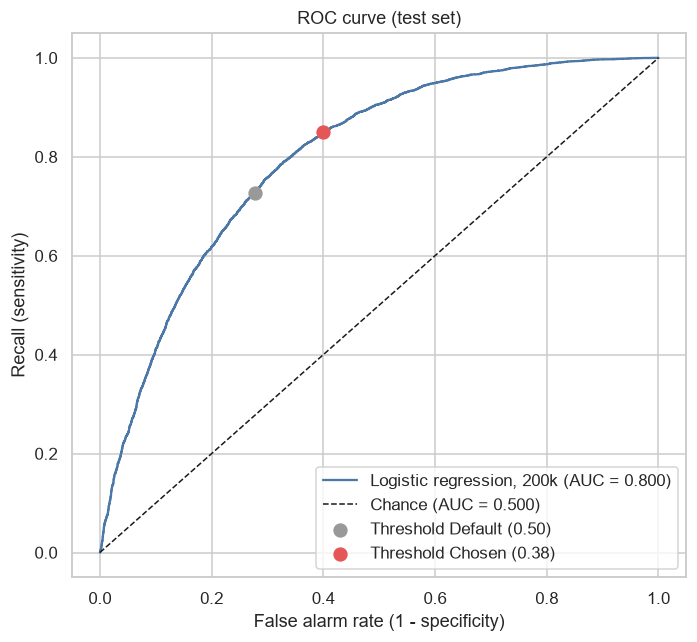

ROC AUC on the test set: 0.800


In [7]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc = roc_auc_score(y_test, proba_test)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color="#4C78A8", label=f"Logistic regression, 200k (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.500)")
for (name, t), color in zip(thresholds_used.items(), ["#999999", "#E45756"]):
    m = results[name]
    ax.scatter(1 - m["Specificity"], m["Recall (sensitivity)"], s=70, color=color, zorder=3,
               label=f"Threshold {name}")
ax.set_xlabel("False alarm rate (1 - specificity)")
ax.set_ylabel("Recall (sensitivity)")
ax.set_title("ROC curve (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"ROC AUC on the test set: {auc:.3f}")

### Interpretation

- **Test ROC AUC:** The model achieves a ROC AUC of **0.800**, indicating good ability to distinguish between people with and without reported diabetes.
- **Threshold independence:** ROC AUC evaluates discrimination across classification thresholds, so changing the threshold from 0.50 to 0.38 does not change this score.
- **Overall:** The result is close to the cross-validation ROC AUC of 0.806, suggesting that test performance is broadly consistent with the training-stage evaluation.

## 9. Training Score Against Test Score

The professor's rule: report **both**. Here the training score is shown in two versions:

- **All 200,000 rows:** includes the synthetic rows. It is optimistic, because synthetic rows are interpolations of the real diabetes people and are easier to fit than real people.
- **Real rows only:** the fair version. The training rows are 100,000 no-diabetes rows and 28,078 diabetes rows, so only Recall, specificity and ROC AUC are directly comparable with the test set. Accuracy, precision and F1 are computed on a 50/50 scale from Recall and specificity for this version.

In [8]:
def scores_5050(y, proba, t):
    """Same metrics, with precision/F1/accuracy on a 50/50 scale (for the unbalanced real training rows)."""
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    tpr, tnr = tp / (tp + fn), tn / (tn + fp)
    prec = tpr / (tpr + (1 - tnr))
    return {"Accuracy": (tpr + tnr) / 2, "Recall (sensitivity)": tpr, "Precision": prec,
            "F1": 2 * prec * tpr / (prec + tpr), "ROC AUC": roc_auc_score(y, proba)}

metrics_to_compare = ["Accuracy", "Recall (sensitivity)", "Precision", "F1", "ROC AUC"]

rows = {}
for name, t in thresholds_used.items():
    train_all = evaluate(y_train, proba_train, t)
    train_real = scores_5050(y_train[is_real], proba_train[is_real], t)
    test_res = evaluate(y_test, proba_test, t)
    for metric in metrics_to_compare:
        rows.setdefault(metric, {})[f"Train (all 200k), {name}"] = train_all[metric]
        rows[metric][f"Train (real rows), {name}"] = train_real[metric]
        rows[metric][f"Test, {name}"] = test_res[metric]

gap_df = pd.DataFrame(rows).T
display(gap_df.round(3))

gaps = {m: gap_df.loc[m, f"Train (real rows), {chosen_label}"] - gap_df.loc[m, f"Test, {chosen_label}"]
        for m in gap_df.index}
print(f"Largest gap between the training (real rows) and test score at the chosen threshold: "
      f"{max(gaps.values(), key=abs):+.4f}")

,"Train (all 200k), Default (0.50)","Train (real rows), Default (0.50)","Test, Default (0.50)","Train (all 200k), Chosen (0.38)","Train (real rows), Chosen (0.38)","Test, Chosen (0.38)"
Accuracy,0.745,0.731,0.724,0.736,0.728,0.725
Recall (sensitivity),0.763,0.736,0.727,0.867,0.850,0.849
Precision,0.737,0.729,0.724,0.687,0.683,0.680
F1,0.750,0.733,0.725,0.767,0.757,0.755
ROC AUC,0.821,0.807,0.800,0.821,0.807,0.800


Largest gap between the training (real rows) and test score at the chosen threshold: +0.0067


### Interpretation

- **Training vs. test performance:** The real-row training metrics are close to the test metrics at both thresholds, suggesting consistent performance on the held-out test set.
- **Default threshold (0.50):** Test ROC AUC is 0.800, compared with 0.807 on real training rows. Test Recall is slightly lower at 0.727 versus 0.736 on real training rows.
- **Chosen threshold (0.38):** Test Recall reaches 0.849, close to the real-row training Recall of 0.850. Test F1 is 0.755, compared with 0.757 on real training rows.
- **Train–test gap:** The largest reported gap between real-row training and test metrics at the chosen threshold is only +0.0067, indicating a small difference in this evaluation.
- **All rows vs. real rows:** Metrics calculated on all 200,000 training rows are generally higher than those calculated on real rows only. The real-row results are more informative for assessing performance on real observations.
- **Overall:** The small real-row training-to-test differences provide limited evidence of overfitting in these metrics, but they do not guarantee similar performance on other populations.

## 10. Logistic Regression Against the Baselines (Test Set)

In [9]:
baselines = {
    "Baseline: always no diabetes": DummyClassifier(strategy="constant", constant=0),
    "Baseline: flag everybody": DummyClassifier(strategy="constant", constant=1),
    "Baseline: random guess": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

comparison = {}
for name, m in baselines.items():
    m.fit(X_train, y_train)
    pred, proba = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    comparison[name] = {"Accuracy": accuracy_score(y_test, pred), "Recall": recall_score(y_test, pred),
                        "Precision": precision_score(y_test, pred, zero_division=0),
                        "F1": f1_score(y_test, pred, zero_division=0), "ROC AUC": roc_auc_score(y_test, proba)}

for name in thresholds_used:
    r = results[name]
    comparison[f"Logistic regression, threshold {name}"] = {
        "Accuracy": r["Accuracy"], "Recall": r["Recall (sensitivity)"], "Precision": r["Precision"],
        "F1": r["F1"], "ROC AUC": r["ROC AUC"]}

display(pd.DataFrame(comparison).T.round(3))

,Accuracy,Recall,Precision,F1,ROC AUC
Baseline: always no diabetes,0.500,0.000,0.000,0.000,0.500
Baseline: flag everybody,0.500,1.000,0.500,0.667,0.500
Baseline: random guess,0.499,0.505,0.499,0.502,0.499
"Logistic regression, threshold Default (0.50)",0.724,0.727,0.724,0.725,0.800
"Logistic regression, threshold Chosen (0.38)",0.725,0.849,0.680,0.755,0.800


### Interpretation

- **Baseline comparison:** The three baseline models achieve ROC AUC scores of approximately 0.500, indicating performance close to chance in distinguishing the two classes.
- **Default threshold (0.50):** Logistic regression achieves a test ROC AUC of 0.800, with Recall of 0.727 and F1 of 0.725, substantially outperforming the baselines.
- **Chosen threshold (0.38):** Recall increases to 0.849 and F1 improves to 0.755, while Precision decreases from 0.724 to 0.680.
- **Accuracy:** Accuracy remains nearly unchanged, increasing slightly from 0.724 to 0.725 despite the shift toward detecting more diabetes cases.
- **Overall:** Logistic regression provides stronger predictive performance than the baseline models. The chosen threshold favors finding more potential cases, with the trade-off of more false-positive predictions.

## 11. How Certain Are These Results?

Bootstrap: 1,000 new samples of the test rows (with replacement), metrics recomputed each time, 95% confidence interval from the middle 95%. The intervals are for the chosen threshold. **These intervals are needed for `08_model_comparison`**: if the 70k and 200k intervals overlap heavily, the two models are not clearly different.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr, p_arr = y_test.to_numpy(), proba_test
n = len(y_arr)

boot = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    yb, pb = y_arr[idx], p_arr[idx]
    tn, fp, fn, tp = confusion_matrix(yb, (pb >= THRESHOLD).astype(int)).ravel()
    boot.append({"Recall": tp / (tp + fn), "Specificity": tn / (tn + fp),
                 "Precision": tp / (tp + fp), "ROC AUC": roc_auc_score(yb, pb)})
boot = pd.DataFrame(boot)

point = results[chosen_label]
ci = pd.DataFrame({
    "Estimate": [point["Recall (sensitivity)"], point["Specificity"], point["Precision"], point["ROC AUC"]],
    "95% CI low": boot.quantile(0.025).values,
    "95% CI high": boot.quantile(0.975).values,
}, index=["Recall", "Specificity", "Precision", "ROC AUC"])
display(ci.round(3))

,Estimate,95% CI low,95% CI high
Recall,0.849,0.841,0.857
Specificity,0.600,0.588,0.611
Precision,0.680,0.669,0.690
ROC AUC,0.800,0.792,0.807


### Interpretation

- **Recall:** The estimated Recall is 0.849, with a 95% confidence interval of 0.841–0.857. This indicates consistently high detection of diabetes cases within the test sample.
- **Specificity:** Specificity is 0.600, with a 95% confidence interval of 0.588–0.611, indicating more limited identification of people without reported diabetes.
- **Precision:** Precision is 0.680, with a 95% confidence interval of 0.669–0.690. This reflects the proportion of flagged individuals who belong to the diabetes class in this test set.
- **ROC AUC:** The estimated ROC AUC is 0.800, with a 95% confidence interval of 0.792–0.807, indicating good discrimination between the two classes.
- **Overall:** The intervals are relatively narrow, suggesting the estimates are reasonably precise for this test sample. They do not guarantee the same performance in other populations.

## 12. Can the Probabilities Be Trusted? (Calibration)

The model was trained on 50/50 data, so these probabilities are on a **balanced scale**.

,Mean predicted probability,Share who actually have diabetes
Group 1,0.064,0.053
Group 2,0.150,0.145
Group 3,0.245,0.276
Group 4,0.349,0.385
Group 5,0.452,0.521
Group 6,0.551,0.581
Group 7,0.641,0.660
Group 8,0.729,0.743
Group 9,0.815,0.787
Group 10,0.909,0.849


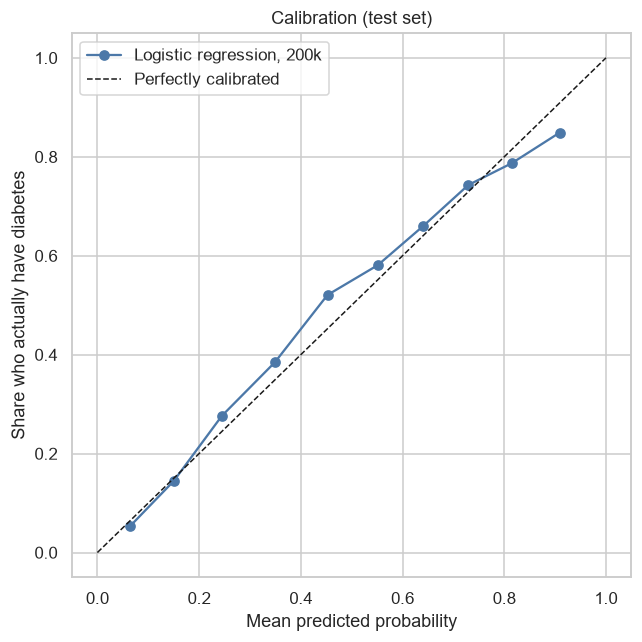

Brier score: 0.182


In [11]:
frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")

calib = pd.DataFrame({"Mean predicted probability": mean_pred,
                      "Share who actually have diabetes": frac_pos})
calib.index = [f"Group {i}" for i in range(1, len(calib) + 1)]
display(calib.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(mean_pred, frac_pos, marker="o", color="#4C78A8", label="Logistic regression, 200k")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Share who actually have diabetes")
ax.set_title("Calibration (test set)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Brier score: {brier_score_loss(y_test, proba_test):.3f}")

### Interpretation

- **Calibration:** The predicted probabilities generally follow the perfectly calibrated reference line, suggesting that the model's predicted risks are reasonably aligned with the observed outcomes.
- **Slight deviations:** Some points fall above the reference line, indicating underestimation of the actual diabetes rate in those probability ranges. Points below the line indicate overestimation.
- **Overall assessment:** The model shows reasonably good calibration on the test set, although small differences remain across probability ranges.
- **Limitation:** Calibration results reflect this test sample and may differ in other populations.

## 13. What the Threshold Means in Practice (Per 1,000 People Screened)

In [12]:
rows = []
for name, t in thresholds_used.items():
    m = results[name]
    tpr, false_alarm_rate = m["Recall (sensitivity)"], 1 - m["Specificity"]
    n_pos = 1000 * REAL_PREVALENCE
    n_neg = 1000 - n_pos
    found = n_pos * tpr
    flagged_healthy = n_neg * false_alarm_rate
    rows.append({
        "Threshold": name,
        "Have diabetes": n_pos,
        "Found": found,
        "Missed": n_pos - found,
        "Healthy people flagged": flagged_healthy,
        "Total flagged": found + flagged_healthy,
        "Share with diabetes among those flagged": found / (found + flagged_healthy),
    })
display(pd.DataFrame(rows).round(2).style.hide(axis="index"))

Threshold,Have diabetes,Found,Missed,Healthy people flagged,Total flagged,Share with diabetes among those flagged
Default (0.50),140.000000,101.720000,38.280000,238.770000,340.490000,0.300000
Chosen (0.38),140.000000,118.900000,21.100000,344.000000,462.900000,0.260000


### Interpretation

- **Threshold comparison:** The chosen threshold (0.38) detects approximately 119 out of 140 diabetes cases per 1,000 people, compared with 102 using the default threshold (0.50).
- **Trade-off:** The lower threshold reduces missed cases from approximately 38 to 21 but increases healthy people flagged from approximately 239 to 344. The share of flagged people who have diabetes also decreases from 30% to 26%.

## 14. Does the Model Work Equally Well for Different Groups?

In [13]:
test_all = test_df.copy()
test_all["proba"] = proba_test
test_all["pred"] = (proba_test >= THRESHOLD).astype(int)
test_all["Age group"] = pd.cut(test_all["Age"], bins=[0, 5, 9, 13],
                               labels=["18-44 (codes 1-5)", "45-64 (codes 6-9)", "65+ (codes 10-13)"])
test_all["Sex group"] = test_all["Sex"].map({0: "Female", 1: "Male"})

rows = []
for col in ["Sex group", "Age group"]:
    for level, g in test_all.groupby(col, observed=True):
        tn, fp, fn, tp = confusion_matrix(g[TARGET], g["pred"], labels=[0, 1]).ravel()
        rows.append({
            "Group": f"{col.replace(' group', '')}: {level}",
            "People": len(g),
            "% with diabetes": g[TARGET].mean() * 100,
            "Recall": tp / (tp + fn) if (tp + fn) else np.nan,
            "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "ROC AUC": roc_auc_score(g[TARGET], g["proba"]) if g[TARGET].nunique() == 2 else np.nan,
        })
display(pd.DataFrame(rows).round(3).style.hide(axis="index"))

Group,People,% with diabetes,Recall,Specificity,ROC AUC
Sex: Female,7644,48.325000,0.849000,0.634000,0.817000
Sex: Male,6395,51.994000,0.849000,0.556000,0.778000
Age: 18-44 (codes 1-5),2153,21.366000,0.593000,0.874000,0.824000
Age: 45-64 (codes 6-9),5977,49.189000,0.820000,0.617000,0.788000
Age: 65+ (codes 10-13),5909,61.246000,0.905000,0.374000,0.740000


### Interpretation

- **Sex:** Recall is the same for females and males (0.849), but specificity and ROC AUC are higher for females, indicating better identification of people without diabetes and slightly better overall discrimination.
- **Age:** The model performs differently across age groups. Recall is highest among adults aged 65+ (0.905) but specificity is lowest (0.374). For ages 18–44, recall is lower (0.593), while specificity is highest (0.874).
- **Overall:** These differences suggest that the model's performance varies across demographic groups, so subgroup results should be considered when evaluating its suitability for screening.

## 15. Predict. Using the Model on New People

The same three hypothetical respondents as in the 70k notebook, so the two models' outputs can be compared person by person.

In [14]:
def adjust_probability(p, prevalence=REAL_PREVALENCE):
    """Convert a probability from the balanced (50/50) scale to the real prevalence."""
    odds = p / (1 - p) * (prevalence / (1 - prevalence))
    return odds / (1 + odds)

def predict_risk(answers):
    row = pd.DataFrame([answers])[FEATURES]
    p = float(model.predict_proba(row)[:, 1][0])
    return {
        "Model probability (balanced data)": p,
        f"Adjusted to {REAL_PREVALENCE:.0%} prevalence": adjust_probability(p),
        "Flagged for follow-up": p >= THRESHOLD,
    }

people = {
    "Person A: 32 years old, healthy": {
        "HighBP": 0, "HighChol": 0, "CholCheck": 1, "BMI": 23, "Smoker": 0, "Stroke": 0,
        "HeartDiseaseorAttack": 0, "PhysActivity": 1, "Fruits": 1, "Veggies": 1, "HvyAlcoholConsump": 0,
        "AnyHealthcare": 1, "NoDocbcCost": 0, "GenHlth": 1, "MentHlth": 0, "PhysHlth": 0, "DiffWalk": 0,
        "Sex": 0, "Age": 3, "Education": 6, "Income": 7},
    "Person B: 57 years old, some risk factors": {
        "HighBP": 1, "HighChol": 0, "CholCheck": 1, "BMI": 31, "Smoker": 1, "Stroke": 0,
        "HeartDiseaseorAttack": 0, "PhysActivity": 1, "Fruits": 0, "Veggies": 1, "HvyAlcoholConsump": 0,
        "AnyHealthcare": 1, "NoDocbcCost": 0, "GenHlth": 3, "MentHlth": 2, "PhysHlth": 3, "DiffWalk": 0,
        "Sex": 1, "Age": 8, "Education": 4, "Income": 5},
    "Person C: 72 years old, several risk factors": {
        "HighBP": 1, "HighChol": 1, "CholCheck": 1, "BMI": 38, "Smoker": 0, "Stroke": 0,
        "HeartDiseaseorAttack": 1, "PhysActivity": 0, "Fruits": 0, "Veggies": 0, "HvyAlcoholConsump": 0,
        "AnyHealthcare": 1, "NoDocbcCost": 1, "GenHlth": 4, "MentHlth": 5, "PhysHlth": 15, "DiffWalk": 1,
        "Sex": 1, "Age": 11, "Education": 3, "Income": 2},
}
display(pd.DataFrame({name: predict_risk(a) for name, a in people.items()}).T.round(3))

,Model probability (balanced data),Adjusted to 14% prevalence,Flagged for follow-up
"Person A: 32 years old, healthy",0.029072,0.004851,False
"Person B: 57 years old, some risk factors",0.543556,0.162381,True
"Person C: 72 years old, several risk factors",0.943314,0.730388,True


### Interpretation

- **Risk examples:** Person A has a low adjusted probability (0.029) and is not flagged, while Persons B and C have higher adjusted probabilities (0.162 and 0.730) and are flagged for follow-up.
- **Overall:** Adjusting probabilities to a 14% diabetes prevalence lowers the estimated risks compared with the balanced-data probabilities. These examples illustrate how the model may support preliminary screening, not diagnosis.

## 16. Save the Results

In [15]:
out = results.T.reset_index().rename(columns={"index": "Threshold"})
out.insert(0, "Model", "Logistic regression (200k: real + synthetic)")
out.to_sql(RESULTS_TABLE, con=engine, if_exists="replace", index=False)

with engine.connect() as conn:
    saved_rows = conn.execute(text(f"SELECT COUNT(*) FROM {RESULTS_TABLE}")).scalar()

print(f"Results saved: {saved_rows} rows in '{RESULTS_TABLE}'.")

Results saved: 2 rows in 'diabetes_eval_logreg_200k'.


## 17. Summary

**What we did in this notebook**

1. Loaded the model saved in `02_train` without retraining and opened the real test set (14,039 rows, the same test set used for the 70k model).
2. Evaluated the model using the default threshold (0.50) and the chosen threshold (0.38).
3. Reported classification metrics, confusion matrices, classification reports, and ROC AUC.
4. Compared training and test performance and evaluated the model against three baselines.
5. Examined confidence intervals, calibration, hypothetical screening results per 1,000 people, and performance across sex and age groups.
6. Tested three hypothetical respondents and prepared results for `08_model_comparison`.

**Key results (test set, chosen threshold)**

- **Recall:** 0.849 (95% CI: 0.841–0.857). **Specificity:** 0.600. **Precision:** 0.680. **F1:** 0.755.
- **ROC AUC:** 0.800 (95% CI: 0.792–0.807). **Accuracy:** 0.725.
- **Default threshold (0.50):** Recall 0.727 and precision 0.724.
- **Training vs. test:** The largest reported gap between real-training and test performance at the chosen threshold is 0.0067. This suggests similar performance, but does not prove the absence of overfitting.
- **Baselines:** The logistic regression model outperforms all three baselines in ROC AUC (0.800 vs. approximately 0.500).
- **Per 1,000 people screened (assuming 14% prevalence):** Approximately 463 flagged, 119 diabetes cases found, 21 missed, and 344 healthy people flagged.
- **Calibration:** Observed diabetes rates generally increase with predicted probabilities, although the model underestimates risk in some groups and overestimates it in the highest-probability groups. **Brier score:** 0.182.
- **Demographic groups:** Recall is equal for females and males (0.849). By age, recall is 0.593 for ages 18–44, 0.820 for ages 45–64, and 0.905 for ages 65+. The target recall of 85% is not met in the youngest group.

**For `08_model_comparison`**

- Compare the 70k and 200k models on the **same test set**. The 200k model has ROC AUC 0.800 and recall 0.849 at the chosen threshold. Insert the corresponding 70k results from its evaluation notebook.
- Compare the 95% confidence intervals for both models to assess the uncertainty around their estimates.
- The 200k model uses the same real diabetes cases as the 70k model, with additional synthetic diabetes rows and real no-diabetes rows. Differences in performance should be evaluated rather than automatically attributed to a single factor.

**Limitations**

- The data are self-reported, and the target represents a *diagnosed* condition.
- The test set is balanced, so precision and accuracy may not reflect performance at the lower prevalence expected in a real screening population. The per-1,000 results are hypothetical estimates.
- Raw model probabilities are based on balanced training data. Prevalence-adjusted probabilities should be clearly distinguished from raw probabilities in the application.
- Approximately 72% of the diabetes class in training is synthetic (see `01_prepare_synthetic`).

**Next step:** `08_model_comparison`.